In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_log_error, r2_score

In [2]:
df_train = pd.read_csv('train.csv')
df_train.head()

,id,season_code,flag_holiday,flag_working,category_weather,feature_temp,feature_feel_temp,feature_humidity,feature_wind,demand,Year,Hour,Day_of_Week,Month
0,1,4,0,1,2,0.26,0.2576,0.70,0.1642,34,2012,2,4,11
1,2,4,0,1,1,0.58,0.5455,0.64,0.0000,341,2012,11,3,10
2,3,4,0,0,3,0.22,0.1970,0.93,0.3284,67,2011,17,6,10
3,4,1,0,1,2,0.36,0.3636,0.66,0.1045,40,2011,1,3,12
4,5,1,0,0,2,0.04,0.0606,0.41,0.1642,96,2011,10,6,1


In [3]:
df_train.sample(10)

,id,season_code,flag_holiday,flag_working,category_weather,feature_temp,feature_feel_temp,feature_humidity,feature_wind,demand,Year,Hour,Day_of_Week,Month
8726,8727,1,0,1,2,0.34,0.3182,0.53,0.2239,33,2011,2,4,2
6546,6547,4,0,1,1,0.22,0.2727,0.80,NaN,28,2011,4,5,12
148,149,1,0,1,2,0.30,0.3182,0.87,0.1045,174,2012,11,4,1
10025,10026,4,0,1,3,0.36,0.3333,0.76,0.2836,29,2012,3,2,12
10087,10088,4,0,1,2,0.72,0.6667,NaN,0.0000,666,2012,16,3,10
2898,2899,2,0,1,1,0.40,0.4091,0.50,0.0000,818,2012,8,5,4
6358,6359,2,0,1,1,0.56,0.5303,0.73,0.2537,79,2012,0,1,6
12023,12024,4,0,0,1,0.32,0.2879,0.53,0.3582,214,2012,20,0,11
9322,9323,2,0,1,1,0.52,0.5000,0.63,0.2239,37,2011,2,3,6
4728,4729,2,0,1,1,0.60,0.5606,0.83,0.1642,68,2012,1,3,5


In [4]:
df_train.shape

(12165, 14)

In [5]:
df_train.columns

Index(['id', 'season_code', 'flag_holiday', 'flag_working', 'category_weather',
       'feature_temp', 'feature_feel_temp', 'feature_humidity', 'feature_wind',
       'demand', 'Year', 'Hour', 'Day_of_Week', 'Month'],
      dtype='str')

In [6]:
df_train.dtypes

id                     int64
season_code            int64
flag_holiday           int64
flag_working           int64
category_weather       int64
feature_temp         float64
feature_feel_temp    float64
feature_humidity     float64
feature_wind         float64
demand                 int64
Year                   int64
Hour                   int64
Day_of_Week            int64
Month                  int64
dtype: object

In [7]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 12165 entries, 0 to 12164
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 12165 non-null  int64  
 1   season_code        12165 non-null  int64  
 2   flag_holiday       12165 non-null  int64  
 3   flag_working       12165 non-null  int64  
 4   category_weather   12165 non-null  int64  
 5   feature_temp       12165 non-null  float64
 6   feature_feel_temp  12165 non-null  float64
 7   feature_humidity   11557 non-null  float64
 8   feature_wind       11557 non-null  float64
 9   demand             12165 non-null  int64  
 10  Year               12165 non-null  int64  
 11  Hour               12165 non-null  int64  
 12  Day_of_Week        12165 non-null  int64  
 13  Month              12165 non-null  int64  
dtypes: float64(4), int64(10)
memory usage: 1.3 MB


In [8]:
df_train.describe()

,id,season_code,flag_holiday,flag_working,category_weather,feature_temp,feature_feel_temp,feature_humidity,feature_wind,demand,Year,Hour,Day_of_Week,Month
count,12165.000000,12165.000000,12165.000000,12165.000000,12165.000000,12165.000000,12165.000000,11557.000000,11557.000000,12165.000000,12165.000000,12165.000000,12165.000000,12165.000000
mean,6083.000000,2.500534,0.028442,0.685656,1.425072,0.497197,0.475919,0.626863,0.189611,279.223263,2011.501192,11.573120,3.002466,6.541060
std,3511.877347,1.109777,0.166239,0.464273,0.637076,0.192414,0.171508,0.193058,0.121757,241.989716,0.500019,6.907753,2.000697,3.439269
min,1.000000,1.000000,0.000000,0.000000,1.000000,0.020000,0.015200,0.000000,0.000000,26.000000,2011.000000,0.000000,0.000000,1.000000
25%,3042.000000,2.000000,0.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,79.000000,2011.000000,6.000000,1.000000,4.000000
50%,6083.000000,3.000000,0.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,218.000000,2012.000000,12.000000,3.000000,7.000000
75%,9124.000000,3.000000,0.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,402.000000,2012.000000,18.000000,5.000000,10.000000
max,12165.000000,4.000000,1.000000,1.000000,4.000000,0.980000,1.000000,1.000000,0.850700,1334.000000,2012.000000,23.000000,6.000000,12.000000


In [9]:
df_train.isnull().sum()

id                     0
season_code            0
flag_holiday           0
flag_working           0
category_weather       0
feature_temp           0
feature_feel_temp      0
feature_humidity     608
feature_wind         608
demand                 0
Year                   0
Hour                   0
Day_of_Week            0
Month                  0
dtype: int64

In [10]:
df_train.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
12160    False
12161    False
12162    False
12163    False
12164    False
Length: 12165, dtype: bool

In [11]:
df_train.duplicated().sum()

np.int64(0)

In [12]:
df_train.nunique()

id                   12165
season_code              4
flag_holiday             2
flag_working             2
category_weather         4
feature_temp            49
feature_feel_temp       64
feature_humidity        87
feature_wind            29
demand                 830
Year                     2
Hour                    24
Day_of_Week              7
Month                   12
dtype: int64

In [13]:
df_test = pd.read_csv("test.csv")
df_test.head()

,id,season_code,flag_holiday,flag_working,category_weather,feature_temp,feature_feel_temp,feature_humidity,feature_wind,Year,Hour,Day_of_Week,Month
0,12166,3,0,1,2,0.62,0.5909,0.78,0.1642,2011,6,1,6
1,12167,2,0,1,1,0.70,0.6667,0.79,NaN,2012,0,2,5
2,12168,4,0,1,1,0.32,0.3030,0.45,0.2537,2011,14,4,12
3,12169,1,1,0,2,0.16,0.1515,0.55,0.1940,2011,11,1,1
4,12170,1,0,1,1,0.52,0.5000,0.63,0.0896,2012,1,3,3


In [14]:
df_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 5214 entries, 0 to 5213
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5214 non-null   int64  
 1   season_code        5214 non-null   int64  
 2   flag_holiday       5214 non-null   int64  
 3   flag_working       5214 non-null   int64  
 4   category_weather   5214 non-null   int64  
 5   feature_temp       5214 non-null   float64
 6   feature_feel_temp  5214 non-null   float64
 7   feature_humidity   4953 non-null   float64
 8   feature_wind       4953 non-null   float64
 9   Year               5214 non-null   int64  
 10  Hour               5214 non-null   int64  
 11  Day_of_Week        5214 non-null   int64  
 12  Month              5214 non-null   int64  
dtypes: float64(4), int64(9)
memory usage: 529.7 KB


In [15]:
df_test.isnull().sum()

id                     0
season_code            0
flag_holiday           0
flag_working           0
category_weather       0
feature_temp           0
feature_feel_temp      0
feature_humidity     261
feature_wind         261
Year                   0
Hour                   0
Day_of_Week            0
Month                  0
dtype: int64

In [16]:
dependence = ['season_code', 'category_weather']
cols_to_impute = ['feature_wind', 'feature_humidity']

for col in cols_to_impute:
    df_train[col] = df_train[col].fillna(
        df_train.groupby(dependence)[col].transform('median')
    )
    df_train[col] = df_train[col].fillna(df_train[col].median())

group_medians = (
    df_train.groupby(dependence)[cols_to_impute]
    .median()
    .reset_index()
)

df_test = df_test.merge(
    group_medians,
    on=dependence,
    how='left',
    suffixes=('', '_median')
)

for col in cols_to_impute:
    df_test[col] = df_test[col].fillna(df_test[f'{col}_median'])
    df_test[col] = df_test[col].fillna(df_train[col].median())

df_test.drop(
    columns=[f'{col}_median' for col in cols_to_impute],
    inplace=True
)

In [17]:
df_train.isnull().sum()

id                   0
season_code          0
flag_holiday         0
flag_working         0
category_weather     0
feature_temp         0
feature_feel_temp    0
feature_humidity     0
feature_wind         0
demand               0
Year                 0
Hour                 0
Day_of_Week          0
Month                0
dtype: int64

In [18]:
df_test.isnull().sum()

id                   0
season_code          0
flag_holiday         0
flag_working         0
category_weather     0
feature_temp         0
feature_feel_temp    0
feature_humidity     0
feature_wind         0
Year                 0
Hour                 0
Day_of_Week          0
Month                0
dtype: int64

In [19]:
# sns.pairplot(df_train.drop(columns = 'id'))

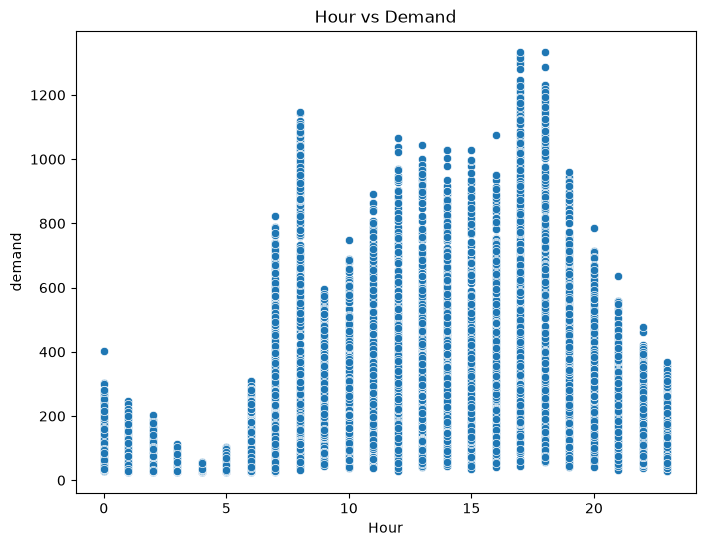

In [20]:
plt.figure(figsize=(8,6))
sns.scatterplot(x='Hour',y='demand',data=df_train)
plt.title("Hour vs Demand")
plt.show()

In [21]:
df_train['hour_sin'] = np.sin(2 * np.pi * df_train['Hour'] / 24.0)
df_train['hour_cos'] = np.cos(2 * np.pi * df_train['Hour'] / 24.0)
df_train['month_sin'] = np.sin(2 * np.pi * df_train['Month'] / 12.0)
df_train['month_cos'] = np.cos(2 * np.pi * df_train['Month'] / 12.0)

df_test['hour_sin'] = np.sin(2 * np.pi * df_test['Hour'] / 24.0)
df_test['hour_cos'] = np.cos(2 * np.pi * df_test['Hour'] / 24.0)
df_test['month_sin'] = np.sin(2 * np.pi * df_test['Month'] / 12.0)
df_test['month_cos'] = np.cos(2 * np.pi * df_test['Month'] / 12.0)

In [22]:
df_train['is_peak'] = df_train['Hour'].isin([7,8,9,17,18,19]).astype(int)
df_train['is_weekend'] = (df_train['Day_of_Week'].isin([0,6])).astype(int)

df_test['is_peak'] = df_test['Hour'].isin([7,8,9,17,18,19]).astype(int)
df_test['is_weekend'] = (df_test['Day_of_Week'].isin([0,6])).astype(int)


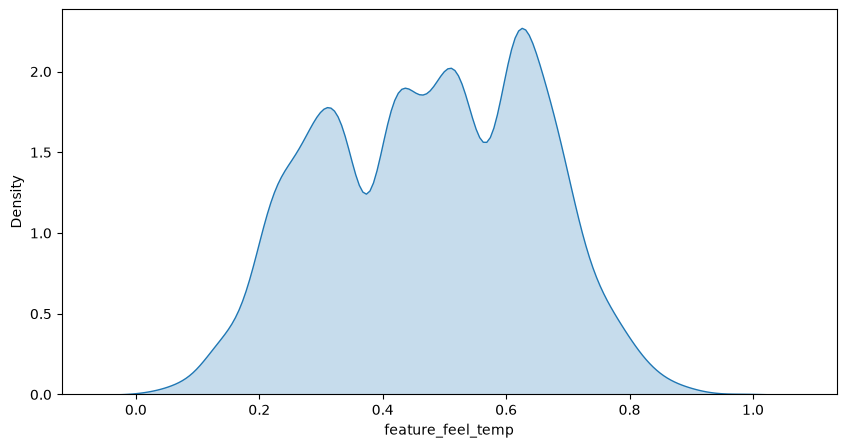

In [23]:
plt.figure(figsize=(10,5))
sns.kdeplot(df_train['feature_feel_temp'],fill=True)
plt.show()

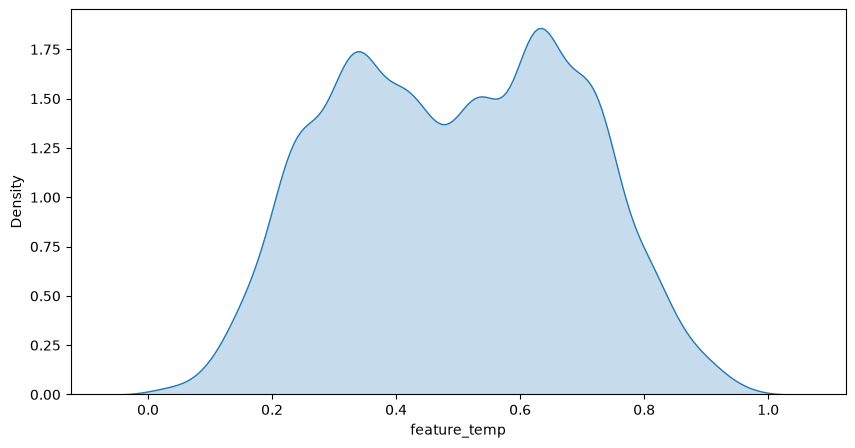

In [24]:
plt.figure(figsize=(10,5))
sns.kdeplot(df_train['feature_temp'],fill=True)
plt.show()

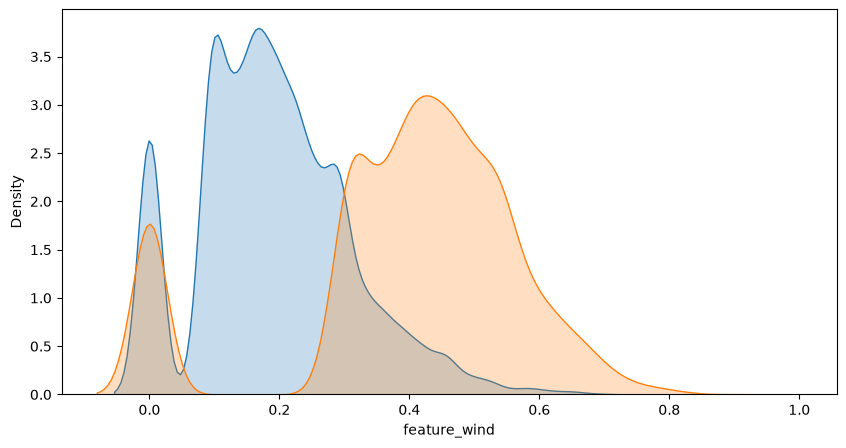

In [25]:
plt.figure(figsize=(10,5))
sns.kdeplot(df_train['feature_wind'],fill=True)
sns.kdeplot(np.sqrt(df_train['feature_wind']),fill=True)

plt.show()

In [26]:
df_train['feature_wind'] = np.sqrt(df_train['feature_wind'])
df_test['feature_wind'] = np.sqrt(df_test['feature_wind'])

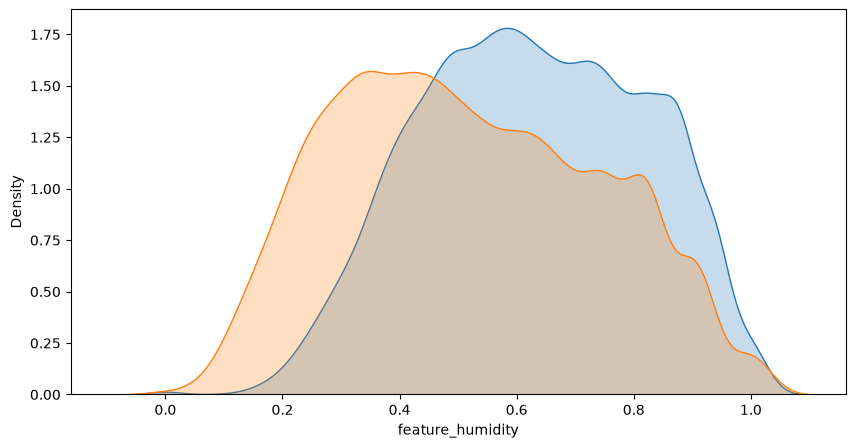

In [27]:
plt.figure(figsize=(10,5))
sns.kdeplot(df_train['feature_humidity'],fill=True)
sns.kdeplot(np.power(df_train['feature_humidity'], 1.5),fill=True)
plt.show()

In [28]:
df_train['feature_humidity'] = np.power(df_train['feature_humidity'], 1.5)
df_test['feature_humidity'] = np.power(df_test['feature_humidity'], 1.5)

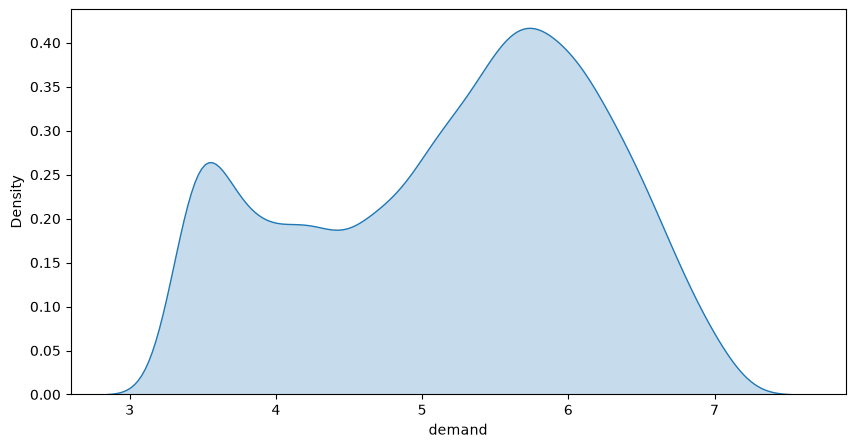

In [29]:
plt.figure(figsize=(10,5))
sns.kdeplot(np.log1p(df_train['demand']),fill=True)

plt.show()

In [30]:
ohe_cols = ['season_code', 'category_weather', 'Day_of_Week', 'Hour', 'Year', 'Month']

for col in ohe_cols:
    if col in df_train.columns:
        df_train[col] = df_train[col].astype(str)
        df_test[col] = df_test[col].astype(str)

df_train = pd.get_dummies(df_train, columns=ohe_cols, drop_first=True, dtype=int)
df_test = pd.get_dummies(df_test, columns=ohe_cols, drop_first=True, dtype=int)


In [31]:
df_train.columns

Index(['id', 'flag_holiday', 'flag_working', 'feature_temp',
       'feature_feel_temp', 'feature_humidity', 'feature_wind', 'demand',
       'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'is_peak',
       'is_weekend', 'season_code_2', 'season_code_3', 'season_code_4',
       'category_weather_2', 'category_weather_3', 'category_weather_4',
       'Day_of_Week_1', 'Day_of_Week_2', 'Day_of_Week_3', 'Day_of_Week_4',
       'Day_of_Week_5', 'Day_of_Week_6', 'Hour_1', 'Hour_10', 'Hour_11',
       'Hour_12', 'Hour_13', 'Hour_14', 'Hour_15', 'Hour_16', 'Hour_17',
       'Hour_18', 'Hour_19', 'Hour_2', 'Hour_20', 'Hour_21', 'Hour_22',
       'Hour_23', 'Hour_3', 'Hour_4', 'Hour_5', 'Hour_6', 'Hour_7', 'Hour_8',
       'Hour_9', 'Year_2012', 'Month_10', 'Month_11', 'Month_12', 'Month_2',
       'Month_3', 'Month_4', 'Month_5', 'Month_6', 'Month_7', 'Month_8',
       'Month_9'],
      dtype='str')

In [32]:
df_train.head()

,id,flag_holiday,flag_working,feature_temp,feature_feel_temp,feature_humidity,feature_wind,demand,hour_sin,hour_cos,...,Month_11,Month_12,Month_2,Month_3,Month_4,Month_5,Month_6,Month_7,Month_8,Month_9
0,1,0,1,0.26,0.2576,0.585662,0.405216,34,0.500000,0.866025,...,1,0,0,0,0,0,0,0,0,0
1,2,0,1,0.58,0.5455,0.512000,0.000000,341,0.258819,-0.965926,...,0,0,0,0,0,0,0,0,0,0
2,3,0,0,0.22,0.1970,0.896860,0.573062,67,-0.965926,-0.258819,...,0,0,0,0,0,0,0,0,0,0
3,4,0,1,0.36,0.3636,0.536187,0.323265,40,0.258819,0.965926,...,0,1,0,0,0,0,0,0,0,0
4,5,0,0,0.04,0.0606,0.262528,0.405216,96,0.500000,-0.866025,...,0,0,0,0,0,0,0,0,0,0


In [33]:
df_test.head()

,id,flag_holiday,flag_working,feature_temp,feature_feel_temp,feature_humidity,feature_wind,hour_sin,hour_cos,month_sin,...,Month_11,Month_12,Month_2,Month_3,Month_4,Month_5,Month_6,Month_7,Month_8,Month_9
0,12166,0,1,0.62,0.5909,0.688877,0.405216,1.000000,6.123234e-17,1.224647e-16,...,0,0,0,0,0,0,1,0,0,0
1,12167,0,1,0.70,0.6667,0.702167,0.440454,0.000000,1.000000e+00,5.000000e-01,...,0,0,0,0,0,1,0,0,0,0
2,12168,0,1,0.32,0.3030,0.301869,0.503686,-0.500000,-8.660254e-01,-2.449294e-16,...,0,1,0,0,0,0,0,0,0,0
3,12169,1,0,0.16,0.1515,0.407891,0.440454,0.258819,-9.659258e-01,5.000000e-01,...,0,0,0,0,0,0,0,0,0,0
4,12170,0,1,0.52,0.5000,0.500047,0.299333,0.258819,9.659258e-01,1.000000e+00,...,0,0,0,1,0,0,0,0,0,0


In [34]:
numeric_df = df_train.drop(columns='id').select_dtypes(include=np.number)
corr = numeric_df.corr()
corr

,flag_holiday,flag_working,feature_temp,feature_feel_temp,feature_humidity,feature_wind,demand,hour_sin,hour_cos,month_sin,...,Month_11,Month_12,Month_2,Month_3,Month_4,Month_5,Month_6,Month_7,Month_8,Month_9
flag_holiday,1.000000,-0.252696,-0.032358,-0.035302,-0.010322,-0.004081,-0.036413,-0.001239,0.002688,-0.008113,...,0.055820,0.013629,0.003271,-0.052148,0.006840,0.006474,-0.051317,0.003864,-0.051623,0.009695
flag_working,-0.252696,1.000000,0.048867,0.047249,0.017249,-0.011838,0.024296,0.004307,-0.001660,0.002182,...,-0.010618,-0.012658,0.003833,0.027322,-0.015638,0.003434,0.023552,-0.016134,0.042937,-0.010591
feature_temp,-0.032358,0.048867,1.000000,0.988547,-0.064564,-0.008644,0.400890,-0.181591,-0.131321,-0.450421,...,-0.203404,-0.271841,-0.295453,-0.170727,-0.041338,0.155346,0.292721,0.412641,0.333158,0.188394
feature_feel_temp,-0.035302,0.047249,0.988547,1.000000,-0.049806,-0.046653,0.397118,-0.174685,-0.124425,-0.442252,...,-0.193605,-0.264378,-0.294119,-0.169479,-0.032294,0.159633,0.285042,0.408826,0.311798,0.182142
feature_humidity,-0.010322,0.017249,-0.064564,-0.049806,1.000000,-0.219311,-0.318492,0.345799,0.262666,-0.140186,...,-0.006230,0.060133,-0.098238,-0.048544,-0.048088,0.094585,-0.074406,-0.053858,0.006305,0.137208
feature_wind,-0.004081,-0.011838,-0.008644,-0.046653,-0.219311,1.000000,0.088908,-0.146678,-0.142809,0.142477,...,-0.030767,-0.030131,0.041235,0.070899,0.085394,0.006605,0.006676,-0.047432,-0.050026,-0.044490
demand,-0.036413,0.024296,0.400890,0.397118,-0.318492,0.088908,1.000000,-0.403918,-0.412544,-0.179648,...,-0.018251,-0.079216,-0.120489,-0.055614,-0.003880,0.042711,0.078620,0.074340,0.085519,0.089151
hour_sin,-0.001239,0.004307,-0.181591,-0.174685,0.345799,-0.146678,-0.403918,1.000000,-0.005314,-0.002141,...,0.003934,0.000102,-0.010394,-0.004040,0.012279,0.008406,-0.005477,0.010310,0.004129,-0.001216
hour_cos,0.002688,-0.001660,-0.131321,-0.124425,0.262666,-0.142809,-0.412544,-0.005314,1.000000,-0.000038,...,0.000796,-0.004863,-0.004445,0.003040,0.004399,0.003658,-0.001789,-0.000520,-0.003977,0.003527
month_sin,-0.008113,0.002182,-0.450421,-0.442252,-0.140186,0.142477,-0.179648,-0.002141,-0.000038,1.000000,...,-0.210169,0.003145,0.361184,0.434522,0.368305,0.218605,0.003099,-0.214106,-0.366698,-0.429128


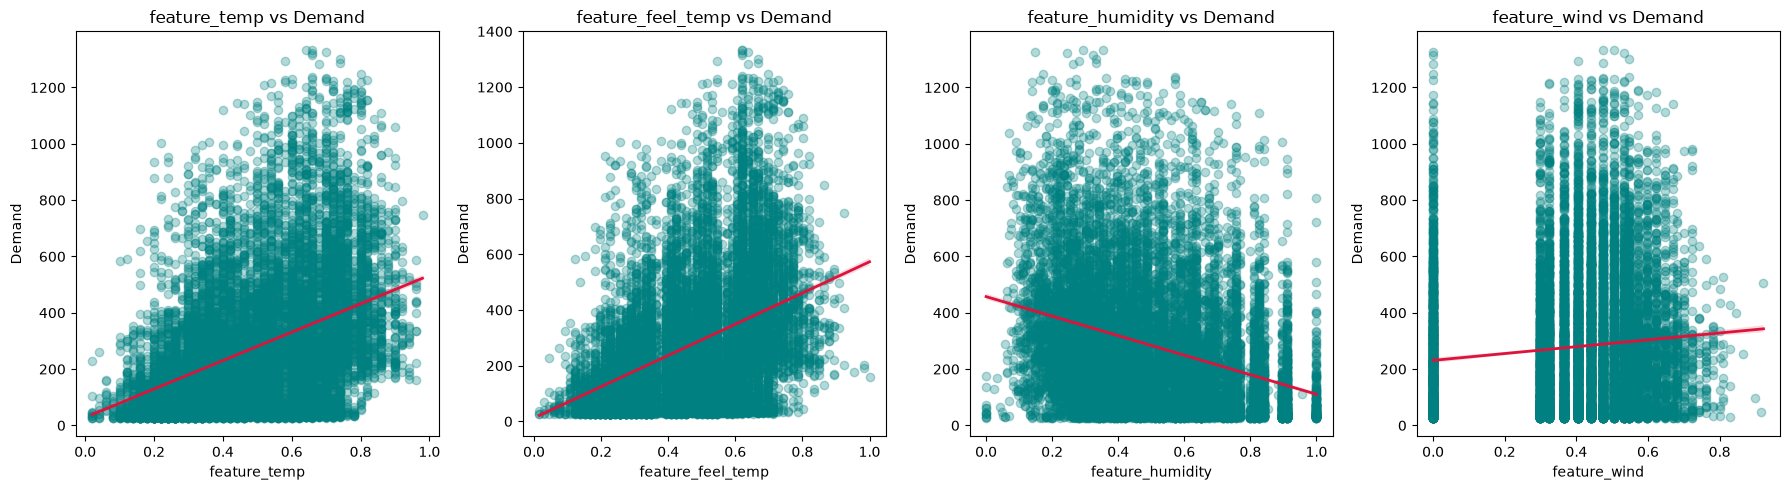

In [35]:
features = ["feature_temp", "feature_feel_temp", "feature_humidity", "feature_wind"]

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for i, col in enumerate(features):
    sns.regplot(
        data=df_train,
        x=col,
        y="demand",
        ax=axes[i],
        scatter_kws={"alpha": 0.3, "color": "teal"},
        line_kws={"color": "crimson", "linewidth": 2},
    )
    axes[i].set_title(f"{col} vs Demand")
    axes[i].set_ylabel("Demand")
    axes[i].set_xlabel(col)

plt.tight_layout()
plt.show()

In [36]:
df_train = df_train.drop(columns = 'feature_temp')
df_test = df_test.drop(columns = 'feature_temp')

In [37]:
df_train['Hour_7_Workday'] = df_train['Hour_7'] * df_train['flag_working']
df_train['Hour_8_Workday'] = df_train['Hour_8'] * df_train['flag_working']
df_train['Hour_9_Workday'] = df_train['Hour_9'] * df_train['flag_working']
df_train['Hour_17_Workday'] = df_train['Hour_17'] * df_train['flag_working']
df_train['Hour_18_Workday'] = df_train['Hour_18'] * df_train['flag_working']
df_train['Hour_19_Workday'] = df_train['Hour_19'] * df_train['flag_working']

df_test['Hour_7_Workday'] = df_test['Hour_7'] * df_test['flag_working']
df_test['Hour_8_Workday'] = df_test['Hour_8'] * df_test['flag_working']
df_test['Hour_9_Workday'] = df_test['Hour_9'] * df_test['flag_working']
df_test['Hour_17_Workday'] = df_test['Hour_17'] * df_test['flag_working']
df_test['Hour_18_Workday'] = df_test['Hour_18'] * df_test['flag_working']
df_test['Hour_19_Workday'] = df_test['Hour_19'] * df_test['flag_working']

In [38]:
df_train['wind_workday'] = df_train['feature_wind'] * df_train['flag_working']
df_test['wind_workday'] = df_test['feature_wind'] * df_test['flag_working']

df_train['humidity_workday'] = df_train['feature_humidity'] * df_train['flag_working']
df_test['humidity_workday'] = df_test['feature_humidity'] * df_test['flag_working']

In [39]:
df_train['feature_feel_temp_square'] = df_train['feature_feel_temp'] ** 2
df_test['feature_feel_temp_square'] = df_test['feature_feel_temp'] ** 2

In [40]:
df_train.columns

Index(['id', 'flag_holiday', 'flag_working', 'feature_feel_temp',
       'feature_humidity', 'feature_wind', 'demand', 'hour_sin', 'hour_cos',
       'month_sin', 'month_cos', 'is_peak', 'is_weekend', 'season_code_2',
       'season_code_3', 'season_code_4', 'category_weather_2',
       'category_weather_3', 'category_weather_4', 'Day_of_Week_1',
       'Day_of_Week_2', 'Day_of_Week_3', 'Day_of_Week_4', 'Day_of_Week_5',
       'Day_of_Week_6', 'Hour_1', 'Hour_10', 'Hour_11', 'Hour_12', 'Hour_13',
       'Hour_14', 'Hour_15', 'Hour_16', 'Hour_17', 'Hour_18', 'Hour_19',
       'Hour_2', 'Hour_20', 'Hour_21', 'Hour_22', 'Hour_23', 'Hour_3',
       'Hour_4', 'Hour_5', 'Hour_6', 'Hour_7', 'Hour_8', 'Hour_9', 'Year_2012',
       'Month_10', 'Month_11', 'Month_12', 'Month_2', 'Month_3', 'Month_4',
       'Month_5', 'Month_6', 'Month_7', 'Month_8', 'Month_9', 'Hour_7_Workday',
       'Hour_8_Workday', 'Hour_9_Workday', 'Hour_17_Workday',
       'Hour_18_Workday', 'Hour_19_Workday', 'wind_workd

In [41]:
df_train.head()

,id,flag_holiday,flag_working,feature_feel_temp,feature_humidity,feature_wind,demand,hour_sin,hour_cos,month_sin,...,Month_9,Hour_7_Workday,Hour_8_Workday,Hour_9_Workday,Hour_17_Workday,Hour_18_Workday,Hour_19_Workday,wind_workday,humidity_workday,feature_feel_temp_square
0,1,0,1,0.2576,0.585662,0.405216,34,0.500000,0.866025,-5.000000e-01,...,0,0,0,0,0,0,0,0.405216,0.585662,0.066358
1,2,0,1,0.5455,0.512000,0.000000,341,0.258819,-0.965926,-8.660254e-01,...,0,0,0,0,0,0,0,0.000000,0.512000,0.297570
2,3,0,0,0.1970,0.896860,0.573062,67,-0.965926,-0.258819,-8.660254e-01,...,0,0,0,0,0,0,0,0.000000,0.000000,0.038809
3,4,0,1,0.3636,0.536187,0.323265,40,0.258819,0.965926,-2.449294e-16,...,0,0,0,0,0,0,0,0.323265,0.536187,0.132205
4,5,0,0,0.0606,0.262528,0.405216,96,0.500000,-0.866025,5.000000e-01,...,0,0,0,0,0,0,0,0.000000,0.000000,0.003672


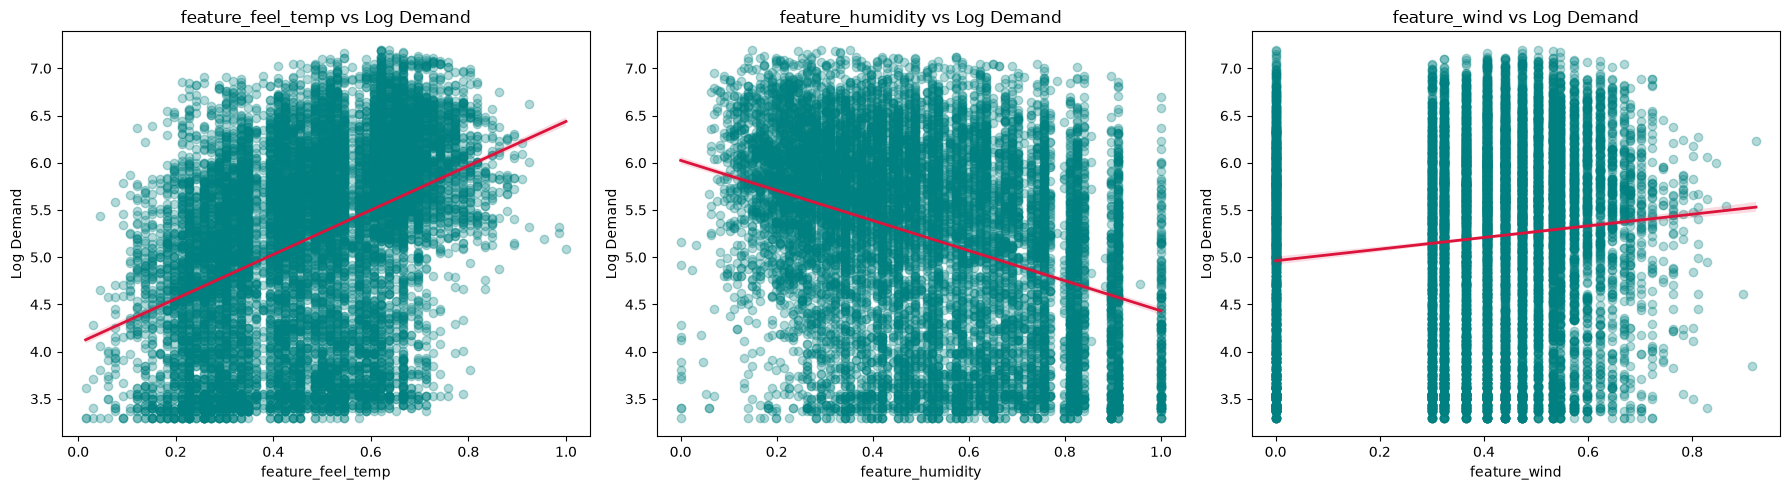

In [42]:
features = ["feature_feel_temp", "feature_humidity", "feature_wind"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(features):
    sns.regplot(
        data=df_train,
        x=col,
        y=np.log1p(df_train["demand"]),
        ax=axes[i],
        scatter_kws={"alpha": 0.3, "color": "teal"},
        line_kws={"color": "crimson", "linewidth": 2},
    )
    axes[i].set_title(f"{col} vs Log Demand")
    axes[i].set_ylabel("Log Demand")
    axes[i].set_xlabel(col)

plt.tight_layout()
plt.show()

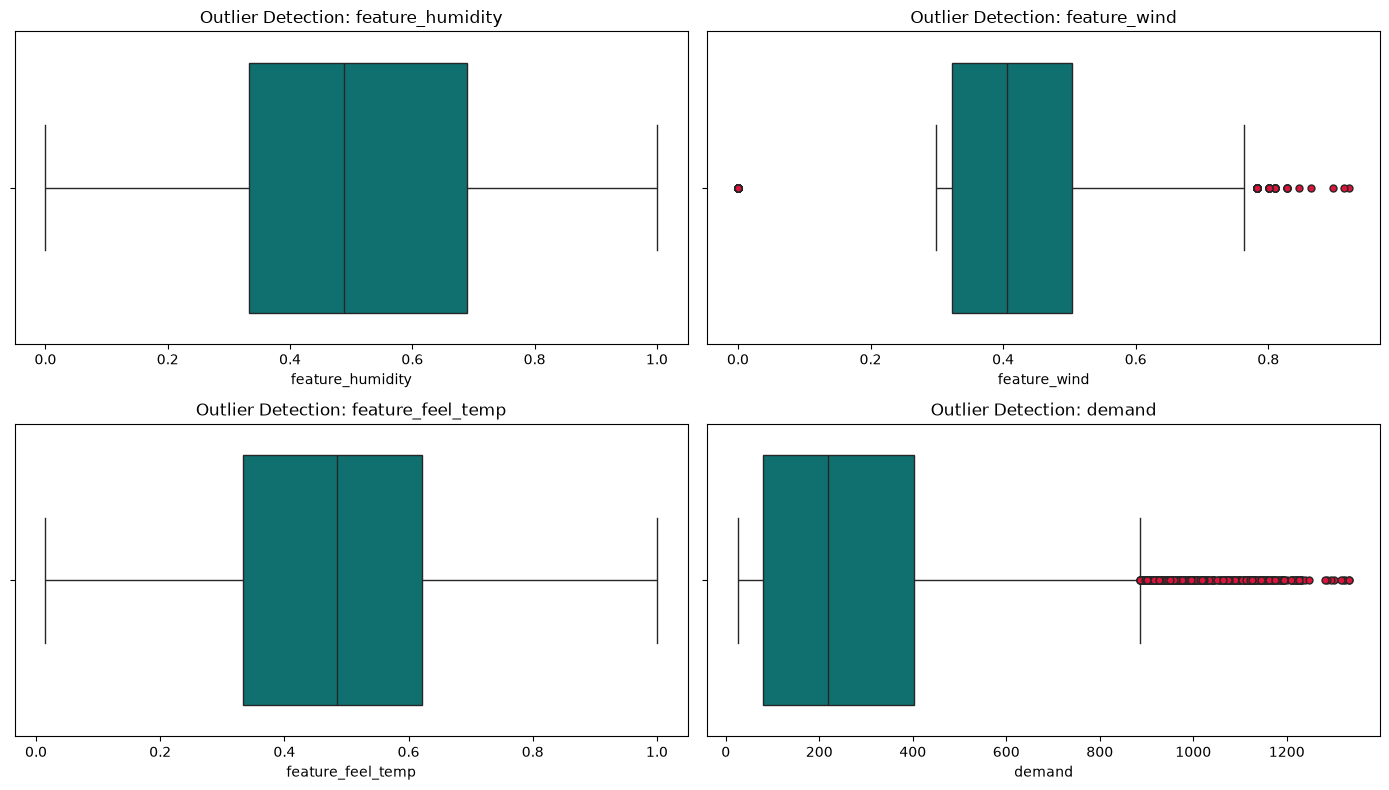

In [43]:
import math
outlier_check_cols = [
    "feature_humidity",
    "feature_wind",
    "feature_feel_temp",
    "demand",
]

num_features = len(outlier_check_cols)
num_cols = 2
num_rows = math.ceil(num_features / num_cols)

fig, axes = plt.subplots(num_rows, num_cols, figsize=(14, 4 * num_rows))
axes = axes.flatten()

for i, col in enumerate(outlier_check_cols):
    if col in df_train.columns:
        sns.boxplot(
            data=df_train,
            x=col,
            ax=axes[i],
            color="teal",
            flierprops={
                "markerfacecolor": "crimson",
                "marker": "o",
                "markersize": 5,
            },
        )
        axes[i].set_title(f"Outlier Detection: {col}")
        axes[i].set_xlabel(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [44]:
lower_wind_bound = 0.15
higher_wind_bound = 0.75

df_train["feature_wind"] = df_train["feature_wind"].clip(
    lower = lower_wind_bound,
    upper = higher_wind_bound
)
df_test["feature_wind"] = df_test["feature_wind"].clip(
    lower = lower_wind_bound,
    upper = higher_wind_bound
)

<Axes: xlabel='feature_wind'>

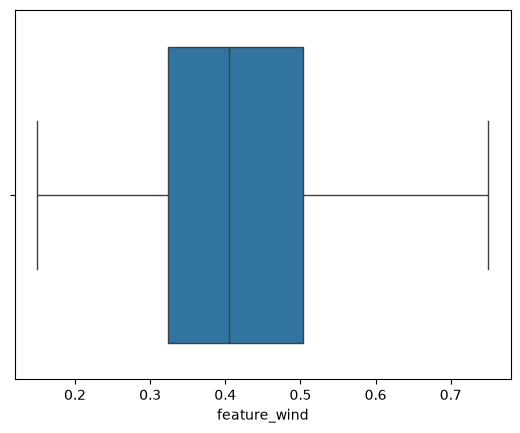

In [45]:
sns.boxplot(x='feature_wind', data=df_train)

In [67]:
new_order = [col for col in df_train.columns if col != 'demand'] + ['demand']
df_train = df_train[new_order]

In [68]:
df_train.sample(10)

,id,flag_holiday,flag_working,feature_feel_temp,feature_humidity,feature_wind,hour_sin,hour_cos,month_sin,month_cos,...,Hour_7_Workday,Hour_8_Workday,Hour_9_Workday,Hour_17_Workday,Hour_18_Workday,Hour_19_Workday,wind_workday,humidity_workday,feature_feel_temp_square,demand
4355,4356,0,1,0.4091,1.000000,0.546352,0.000000,1.000000,8.660254e-01,-0.500000,...,0,0,0,0,0,0,0.546352,1.000000,0.167363,45
7966,7967,0,1,0.6061,0.623712,0.299333,0.500000,-0.866025,1.224647e-16,-1.000000,...,0,0,0,0,0,0,0.299333,0.623712,0.367357,266
6006,6007,0,1,0.6364,0.243555,0.323265,-0.707107,-0.707107,-8.660254e-01,0.500000,...,0,0,0,0,0,0,0.323265,0.243555,0.405005,438
4027,4028,0,1,0.1667,0.715542,0.405216,-0.500000,0.866025,8.660254e-01,0.500000,...,0,0,0,0,0,0,0.405216,0.715542,0.027789,87
11193,11194,0,0,0.5000,0.911364,0.299333,0.707107,-0.707107,5.000000e-01,-0.866025,...,0,0,0,0,0,0,0.000000,0.000000,0.250000,159
7835,7836,0,0,0.2879,0.649519,0.150000,0.965926,-0.258819,-8.660254e-01,0.500000,...,0,0,0,0,0,0,0.000000,0.000000,0.082886,54
3990,3991,0,1,0.6212,0.353553,0.323265,0.000000,1.000000,1.224647e-16,-1.000000,...,0,0,0,0,0,0,0.323265,0.353553,0.385889,97
9535,9536,0,1,0.6667,0.364213,0.473181,-0.707107,-0.707107,8.660254e-01,-0.500000,...,0,0,0,0,0,0,0.473181,0.364213,0.444489,260
3696,3697,0,1,0.8182,0.225062,0.299333,-0.258819,-0.965926,1.224647e-16,-1.000000,...,0,0,0,0,0,0,0.299333,0.225062,0.669451,207
4054,4055,0,0,0.4242,0.911364,0.680221,-0.866025,0.500000,-8.660254e-01,0.500000,...,0,0,0,0,0,0,0.000000,0.000000,0.179946,99


In [69]:
df_train.columns

Index(['id', 'flag_holiday', 'flag_working', 'feature_feel_temp',
       'feature_humidity', 'feature_wind', 'hour_sin', 'hour_cos', 'month_sin',
       'month_cos', 'is_peak', 'is_weekend', 'season_code_2', 'season_code_3',
       'season_code_4', 'category_weather_2', 'category_weather_3',
       'category_weather_4', 'Day_of_Week_1', 'Day_of_Week_2', 'Day_of_Week_3',
       'Day_of_Week_4', 'Day_of_Week_5', 'Day_of_Week_6', 'Hour_1', 'Hour_10',
       'Hour_11', 'Hour_12', 'Hour_13', 'Hour_14', 'Hour_15', 'Hour_16',
       'Hour_17', 'Hour_18', 'Hour_19', 'Hour_2', 'Hour_20', 'Hour_21',
       'Hour_22', 'Hour_23', 'Hour_3', 'Hour_4', 'Hour_5', 'Hour_6', 'Hour_7',
       'Hour_8', 'Hour_9', 'Year_2012', 'Month_10', 'Month_11', 'Month_12',
       'Month_2', 'Month_3', 'Month_4', 'Month_5', 'Month_6', 'Month_7',
       'Month_8', 'Month_9', 'Hour_7_Workday', 'Hour_8_Workday',
       'Hour_9_Workday', 'Hour_17_Workday', 'Hour_18_Workday',
       'Hour_19_Workday', 'wind_workday', 'humi

In [70]:
X = df_train.drop(columns=['id', 'demand'])
y = df_train['demand']

continuous_cols = ['feature_feel_temp', 'feature_humidity', 'feature_wind', 'wind_workday', 'humidity_workday', 'feature_feel_temp_square']

continuous_cols = [col for col in continuous_cols if col in X.columns]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [71]:
y_train_log = np.log1p(y_train)

<Axes: xlabel='demand'>

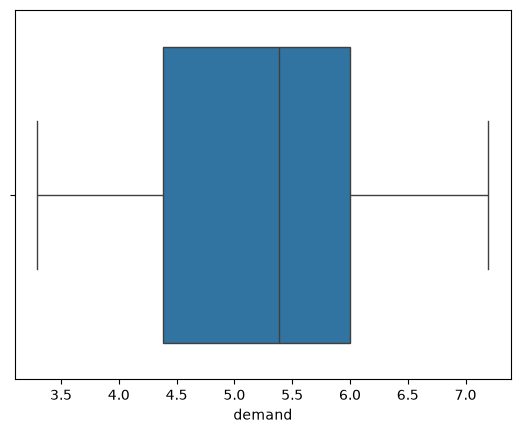

In [72]:
sns.boxplot(x=y_train_log, data=df_train)

In [73]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [96]:
reg = Ridge(alpha=0.05)
reg.fit(X_train, y_train_log)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",0.05
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga'

In [97]:
y_pred_log = reg.predict(X_test)

y_pred = np.expm1(y_pred_log)

In [98]:
r2_score(y_test, y_pred)

0.8559563098133792

In [99]:
root_mean_squared_log_error(y_test, y_pred)

0.35760832412356314

In [100]:
y_full_raw = df_train['demand']
y_full_log = np.log1p(y_full_raw)

X_full = X

X_full_scaled = X.copy()

sscaler = StandardScaler()
X_full_scaled[continuous_cols] = sscaler.fit_transform(X_full[continuous_cols])

model = Ridge(alpha=0.05)

In [101]:
X_full_scaled.shape

(12165, 67)

In [102]:
y_full_log.shape

(12165,)

In [103]:
model.fit(X_full_scaled, y_full_log)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",0.05
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga'

In [104]:
df_test_fresh = pd.read_csv('test.csv')

df_test_aligned = df_test.set_index('id').reindex(df_test_fresh['id']).reset_index()

X_test_final = df_test_aligned.drop(columns=['id', 'demand', 'feature_temp'], errors='ignore')

X_test_final = X_test_final.reindex(columns=X_full.columns, fill_value=0)

X_test_scaled = X_test_final.copy()
X_test_scaled[continuous_cols] = sscaler.transform(X_test_final[continuous_cols])

final_preds_log = model.predict(X_test_scaled)

final_preds_raw = np.expm1(final_preds_log)

final_preds_clean = np.clip(final_preds_raw, 0, None)

submission = pd.DataFrame({
    'id': df_test_fresh['id'].astype(int),
    'demand': final_preds_clean
})

submission.to_csv('submission6.csv', index=False)

submission.head()

,id,demand
0,12166,107.087260
1,12167,127.583897
2,12168,207.321204
3,12169,106.804019
4,12170,63.063265


In [105]:
X_test_final.head()

,flag_holiday,flag_working,feature_feel_temp,feature_humidity,feature_wind,hour_sin,hour_cos,month_sin,month_cos,is_peak,...,Month_9,Hour_7_Workday,Hour_8_Workday,Hour_9_Workday,Hour_17_Workday,Hour_18_Workday,Hour_19_Workday,wind_workday,humidity_workday,feature_feel_temp_square
0,0,1,0.5909,0.688877,0.405216,1.000000,6.123234e-17,1.224647e-16,-1.000000e+00,0,...,0,0,0,0,0,0,0,0.405216,0.688877,0.349163
1,0,1,0.6667,0.702167,0.440454,0.000000,1.000000e+00,5.000000e-01,-8.660254e-01,0,...,0,0,0,0,0,0,0,0.440454,0.702167,0.444489
2,0,1,0.3030,0.301869,0.503686,-0.500000,-8.660254e-01,-2.449294e-16,1.000000e+00,0,...,0,0,0,0,0,0,0,0.503686,0.301869,0.091809
3,1,0,0.1515,0.407891,0.440454,0.258819,-9.659258e-01,5.000000e-01,8.660254e-01,0,...,0,0,0,0,0,0,0,0.000000,0.000000,0.022952
4,0,1,0.5000,0.500047,0.299333,0.258819,9.659258e-01,1.000000e+00,6.123234e-17,0,...,0,0,0,0,0,0,0,0.299333,0.500047,0.250000


In [106]:
X_test_final.columns

Index(['flag_holiday', 'flag_working', 'feature_feel_temp', 'feature_humidity',
       'feature_wind', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos',
       'is_peak', 'is_weekend', 'season_code_2', 'season_code_3',
       'season_code_4', 'category_weather_2', 'category_weather_3',
       'category_weather_4', 'Day_of_Week_1', 'Day_of_Week_2', 'Day_of_Week_3',
       'Day_of_Week_4', 'Day_of_Week_5', 'Day_of_Week_6', 'Hour_1', 'Hour_10',
       'Hour_11', 'Hour_12', 'Hour_13', 'Hour_14', 'Hour_15', 'Hour_16',
       'Hour_17', 'Hour_18', 'Hour_19', 'Hour_2', 'Hour_20', 'Hour_21',
       'Hour_22', 'Hour_23', 'Hour_3', 'Hour_4', 'Hour_5', 'Hour_6', 'Hour_7',
       'Hour_8', 'Hour_9', 'Year_2012', 'Month_10', 'Month_11', 'Month_12',
       'Month_2', 'Month_3', 'Month_4', 'Month_5', 'Month_6', 'Month_7',
       'Month_8', 'Month_9', 'Hour_7_Workday', 'Hour_8_Workday',
       'Hour_9_Workday', 'Hour_17_Workday', 'Hour_18_Workday',
       'Hour_19_Workday', 'wind_workday', 'humidity_w